# Шаг 2. Один нейрон на чистом NumPy: отличаем 0 от 1

Прежде чем брать большую сеть, разберём её «кирпичик» — **один искусственный нейрон** — и обучим его вручную,
без готовых библиотек машинного обучения.

**Как устроен нейрон:**
- у него **784 веса** — по одному на каждый пиксель картинки 28 × 28 — и одно **смещение** `b`;
- он считает **взвешенную сумму**: `z = x₁·w₁ + x₂·w₂ + … + x₇₈₄·w₇₈₄ + b`;
- «сжимает» её **сигмоидой** `σ(z) = 1 / (1 + e⁻ᶻ)` в число от 0 до 1:
  близко к 1 — «это единица», близко к 0 — «это ноль».

Задача простая — отличить только **нули от единиц**, — поэтому одного нейрона хватает.

**Структура ноутбука (алгоритм):**
1. Импортируем NumPy, matplotlib и помощники.
2. Рисуем график сигмоиды — функции активации нейрона.
3. Выбираем из MNIST только нули и единицы, каждую картинку вытягиваем в строку из 784 чисел.
4. Создаём нейрон: веса и смещение равны нулю — он ещё ничего не знает.
5. **Обучаем градиентным спуском**, 100 шагов:
   1. нейрон отвечает на все обучающие картинки;
   2. считаем ошибку каждого ответа (ответ минус правильный);
   3. сдвигаем каждый вес в сторону, уменьшающую ошибку;
   4. каждые 20 шагов проверяем точность на проверочных картинках.
6. Рисуем 784 веса как картинку 28 × 28 и видим, какой «шаблон» выучил нейрон.

In [ ]:
# Настройка для Google Colab. На своём компьютере эта ячейка ничего не делает.
# В Colab нужна папка machine_vision на Google Диске (в ней session01–session05 и dataset).
import os
import sys

try:
    from google.colab import drive
except ImportError:
    drive = None

if drive:
    drive.mount("/content/drive")
    COLAB_ROOT = "/content/drive/MyDrive/machine_vision"
    os.chdir(f"{COLAB_ROOT}/session03")  # здесь лежит common.py и сохраняются результаты
    sys.path.insert(0, os.getcwd())

    # Набор данных скачивается на Диск один раз, потом берётся готовый
    from torchvision import datasets

    datasets.MNIST(f"{COLAB_ROOT}/data", download=True)

## Общий модуль `common.py`

Во всех ноутбуках этой сессии используется модуль `common.py` из этой же папки:

| Имя | Что делает |
|-----|------------|
| `mnist(train)` | скачивает (один раз, ~12 МБ в папку `data`) и возвращает набор MNIST: обучающий (`train=True`, 60 000) или проверочный (`train=False`, 10 000) |
| `MLP` | многослойная сеть: 784 входа → 128 → 64 → 10 выходов |
| `train(model, dataset, epochs)` | цикл обучения из шага 3, без пояснений |
| `predict_all(model, dataset)` | ответы сети (номер цифры) для каждой картинки набора |
| `accuracy(model, dataset)` | доля картинок, на которых сеть ответила верно |
| `load_model()` | загрузить обученную сеть из `mlp.pt` (файл создаёт шаг 3) |
| `show()` | показать графики matplotlib и закрыть их |
| `MODEL_FILE` | путь к файлу `mlp.pt` |

> Ноутбуки нужно запускать из папки `session03`, иначе `import common` не найдёт модуль.
> Нужные библиотеки: `pip install -r requirements.txt`.

## 1. Импорт

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from common import mnist, show

## 2. Функция активации: сигмоида

Взвешенная сумма `z` может быть любым числом — от сильно отрицательного до сильно положительного.
Чтобы превратить её в «уверенность» от 0 до 1, нейрон пропускает `z` через **функцию активации** —
сигмоиду `σ(z) = 1 / (1 + e⁻ᶻ)`.

Что видно на графике:
- при `z = 0` получается ровно `0.5` — «не знаю»;
- чем больше `z`, тем ближе ответ к 1 («это единица»), чем меньше — тем ближе к 0 («это ноль»);
- около нуля кривая крутая: небольшое изменение `z` сильно меняет ответ;
  вдали от нуля — пологая: ответ почти не меняется, нейрон уже «уверен».

`np.linspace(-8, 8, 200)` создаёт 200 равномерно расставленных точек от −8 до 8 — по ним и строим кривую.

In [ ]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))


z = np.linspace(-8, 8, 200)
plt.figure(figsize=(7, 4))
plt.plot(z, sigmoid(z), linewidth=2, label="σ(z) = 1 / (1 + e⁻ᶻ)")
plt.axhline(0.5, color="gray", linestyle="--", linewidth=1)  # порог «не знаю»
plt.axvline(0, color="gray", linestyle="--", linewidth=1)
plt.scatter([0], [0.5], color="red", zorder=3)
plt.annotate("σ(0) = 0.5", (0, 0.5), xytext=(0.6, 0.38))
plt.xlabel("z — взвешенная сумма")
plt.ylabel("σ(z) — ответ нейрона")
plt.title("Сигмоида — функция активации нейрона")
plt.ylim(-0.05, 1.05)
plt.grid(alpha=0.3)
plt.legend(loc="upper left")
plt.show()

## 3. Готовим данные: только нули и единицы

Функция `zeros_and_ones` работает с «сырыми» данными набора, минуя преобразования:
1. `dataset.data` — все картинки сразу, тензор формы `(N, 28, 28)` с числами 0…255.
   `.numpy()` превращает его в массив NumPy, `.reshape(-1, 784)` вытягивает каждую картинку в строку из 784 чисел
   (`-1` — «посчитай сам», это число картинок N), `/ 255` переводит в диапазон 0…1.
2. `dataset.targets` — правильные ответы для всех картинок.
3. `keep = (y == 0) | (y == 1)` — **булева маска**: `True` там, где цифра 0 или 1 (`|` — логическое «или»).
   `x[keep]` оставляет только нужные строки.

Получаем матрицу `x` формы `(N, 784)` — по строке на картинку — и вектор ответов `y` из нулей и единиц.

In [2]:
def zeros_and_ones(dataset):
    """Оставить только нули и единицы; картинки вытянуть в строки по 784 числа."""
    x = dataset.data.numpy().reshape(-1, 784) / 255
    y = dataset.targets.numpy()
    keep = (y == 0) | (y == 1)
    return x[keep], y[keep]


x, y = zeros_and_ones(mnist(train=True))
x_test, y_test = zeros_and_ones(mnist(train=False))
print("Картинок с нулями и единицами:", len(x))
print("Форма x:", x.shape)

Картинок с нулями и единицами: 12665
Форма x: (12665, 784)


## 4. Нейрон

Веса `w` и смещение `b` в начале равны нулю. Значит, для любой картинки сумма `z = 0`, а `σ(0) = 0.5` —
нейрон отвечает «не знаю» с вероятностью 50 на 50.

Функция `neuron(x)` считает ответы **сразу для всех картинок**:
`x @ w` — матричное умножение `(N, 784) @ (784,)` даёт N взвешенных сумм за одну операцию.

In [3]:
w = np.zeros(784)  # веса: сначала нейрон ничего не знает
b = 0.0            # смещение


def neuron(x):
    return 1 / (1 + np.exp(-(x @ w + b)))  # взвешенная сумма → число от 0 до 1

## 5. Обучение градиентным спуском

Идея: ошибку можно уменьшить, если немного сдвинуть каждый вес в «правильную» сторону.
В какую именно — подсказывает **градиент** (производная ошибки по весу).

Для сигмоиды с функцией ошибки «логистическая потеря» (log loss) градиент получается очень простым:

- `error = neuron(x) - y` — ошибка на каждой картинке: насколько ответ больше правильного;
- градиент по весам: `xᵀ @ error / N` — для веса `wⱼ` это среднее по картинкам «яркость пикселя `j` × ошибка».
  Если нейрон завысил ответ (`error > 0`) на картинке, где пиксель `j` яркий, вес `wⱼ` надо уменьшить;
- градиент по смещению — просто средняя ошибка.

Шаг обновления: `вес -= LEARNING_RATE × градиент`. **Скорость обучения** `LEARNING_RATE = 0.5` задаёт величину шага:
слишком маленькая — учится долго, слишком большая — «перепрыгивает» минимум.

Каждые 20 шагов считаем точность на проверочных данных: ответ `> 0.5` считаем «единицей»
и сравниваем с правильным; `.mean()` от массива `True/False` — доля верных.

In [4]:
LEARNING_RATE = 0.5
for step in range(101):
    error = neuron(x) - y                       # насколько ошиблись на каждой картинке
    w -= LEARNING_RATE * x.T @ error / len(x)   # подвинуть каждый вес против ошибки
    b -= LEARNING_RATE * error.mean()
    if step % 20 == 0:
        correct = ((neuron(x_test) > 0.5) == y_test).mean()
        print(f"Шаг {step:3d}: верно на проверке {correct:.1%}")

Шаг   0: верно на проверке 99.6%
Шаг  20: верно на проверке 99.9%
Шаг  40: верно на проверке 99.9%
Шаг  60: верно на проверке 99.9%
Шаг  80: верно на проверке 99.9%
Шаг 100: верно на проверке 99.9%


## 6. Что выучил нейрон: веса как картинка

784 веса — это столько же чисел, сколько пикселей. Сложим их обратно в квадрат 28 × 28 (`w.reshape(28, 28)`)
и раскрасим палитрой `bwr` (blue–white–red):
- **красные** веса положительные: яркий пиксель здесь толкает ответ к «единице»;
- **синие** — отрицательные: яркий пиксель здесь толкает ответ к «нулю»;
- белые — около нуля, пиксель ни на что не влияет (например, края, где цифр не бывает).

`vmin=-limit, vmax=limit` делает шкалу симметричной, чтобы ноль точно был белым.
Обычно видна красная вертикальная палочка в центре (где пишут «1») и синее кольцо вокруг (где пишут «0»).

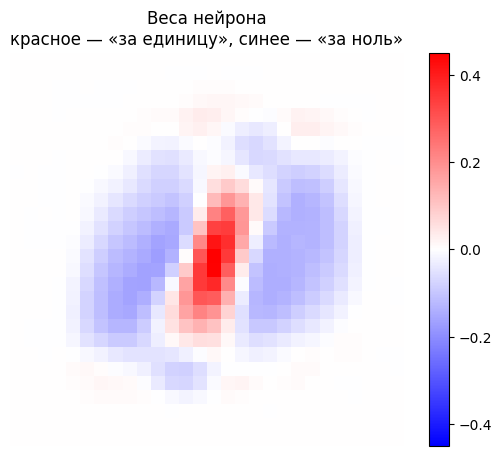

In [5]:
# Веса можно нарисовать как картинку 28×28 — это «шаблон», который выучил нейрон
limit = np.abs(w).max()
plt.figure(figsize=(5.5, 4.6))
plt.imshow(w.reshape(28, 28), cmap="bwr", vmin=-limit, vmax=limit)
plt.colorbar()
plt.title("Веса нейрона\nкрасное — «за единицу», синее — «за ноль»")
plt.axis("off")
plt.tight_layout()
plt.savefig("neuron_weights.png", dpi=100)
show()

## Попробуйте сами

1. Меняйте `LEARNING_RATE`: 0.01, 0.5, 5. Как это влияет на скорость роста точности?
2. Научите нейрон отличать 3 от 8 (поменяйте маску и сделайте `y = (y == 8)`). Точность ниже? Почему?
3. Посмотрите на ответ нейрона для одной картинки: `neuron(x_test[:5])` и `y_test[:5]`.
4. Начните не с нулевых весов, а со случайных: `w = np.random.randn(784) * 0.01`. Как выглядит картинка весов?